In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
import joblib

In [7]:
# 1. Load Dataset (Make sure 'Crop_recommendation.csv' is in your folder)
df = pd.read_csv('Crop_recommendation.csv')

In [8]:
print("Dataset Shape:", df.shape)
print(df.head())

Dataset Shape: (2200, 8)
    N   P   K  temperature   humidity        ph    rainfall label
0  90  42  43    20.879744  82.002744  6.502985  202.935536  rice
1  85  58  41    21.770462  80.319644  7.038096  226.655537  rice
2  60  55  44    23.004459  82.320763  7.840207  263.964248  rice
3  74  35  40    26.491096  80.158363  6.980401  242.864034  rice
4  78  42  42    20.130175  81.604873  7.628473  262.717340  rice


In [9]:
# 2. Split Features (X) and Target (y)
X = df[['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']]
y = df['label']

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [11]:
# 3. Define Models to Compare (for your research paper)
models = {
    "Random Forest": RandomForestClassifier(random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "SVM": SVC(),
    "KNN": KNeighborsClassifier()
}

In [12]:
best_model = None
best_accuracy = 0
best_model_name = ""

In [13]:
print("\n--- Model Evaluation Results ---")


--- Model Evaluation Results ---


In [14]:
for name, model in models.items():
    # Train model
    model.fit(X_train, y_train)
    
    # Predict
    y_pred = model.predict(X_test)
    
    # Evaluate
    acc = accuracy_score(y_test, y_pred)
    print(f"{name} Accuracy: {acc * 100:.2f}%")
    
    # Track the best performing model
    if acc > best_accuracy:
        best_accuracy = acc
        best_model = model
        best_model_name = name

Random Forest Accuracy: 99.32%
Decision Tree Accuracy: 98.64%
SVM Accuracy: 96.14%
KNN Accuracy: 97.05%


In [15]:
print(f"\nBest Model for Deployment: {best_model_name} with {best_accuracy * 100:.2f}% accuracy")


Best Model for Deployment: Random Forest with 99.32% accuracy


In [12]:
# 4. Save the best model for your project web app
joblib.dump(best_model, 'crop_model.pkl')
print("Model saved successfully as 'crop_model.pkl'.")

Model saved successfully as 'crop_model.pkl'.


In [3]:
!python -m pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   --------------------------- ------------ 524.3/751.9 kB 1.9 MB/s eta 0:00:01
   ---------------------------------------- 751.9/751.9 kB 1.6 MB/s eta 0:00:00

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]



In [19]:
import shap
import matplotlib.pyplot as plt

In [20]:
# 1. Use the generic Explainer which auto-detects Tree models correctly
explainer = shap.Explainer(best_model, X_train)
shap_values = explainer(X_test)

Background dataset has 1760 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1760 when initializing the masker.
100%|===================| 9670/9680 [02:42<00:00]        

In [21]:
# 2. Generate and save the summary plot
plt.figure()
shap.summary_plot(shap_values, X_test, show=False)
plt.savefig("shap_analysis.png", bbox_inches='tight')
plt.close()

In [23]:
print("SHAP analysis plot saved successfully as 'shap_analysis.png'!")

SHAP analysis plot saved successfully as 'shap_analysis.png'!


1. Initializing SHAP explainer...
2. Calculating SHAP values for test dataset...
3. Generating and saving summary plot...


IndexError: index 8 is out of bounds for axis 1 with size 7

<Figure size 640x480 with 0 Axes>

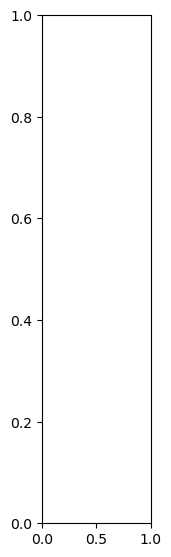

In [24]:
import shap
import matplotlib.pyplot as plt
import os

print("1. Initializing SHAP explainer...")
# Using TreeExplainer configured for tree-based ensemble models
explainer = shap.TreeExplainer(best_model)

print("2. Calculating SHAP values for test dataset...")
shap_values = explainer.shap_values(X_test)

print("3. Generating and saving summary plot...")
plt.figure()
# For multi-class models like Random Forest, shap_values is a list of arrays. 
# We pass X_test as the feature data.
shap.summary_plot(shap_values, X_test, show=False)

output_filename = "shap_analysis.png"
plt.savefig(output_filename, bbox_inches='tight')
plt.close()

# Verify the file exists on your disk
if os.path.exists(output_filename):
    print(f"Success! File '{output_filename}' is saved in: {os.getcwd()}")
else:
    print("Warning: File was not found.")

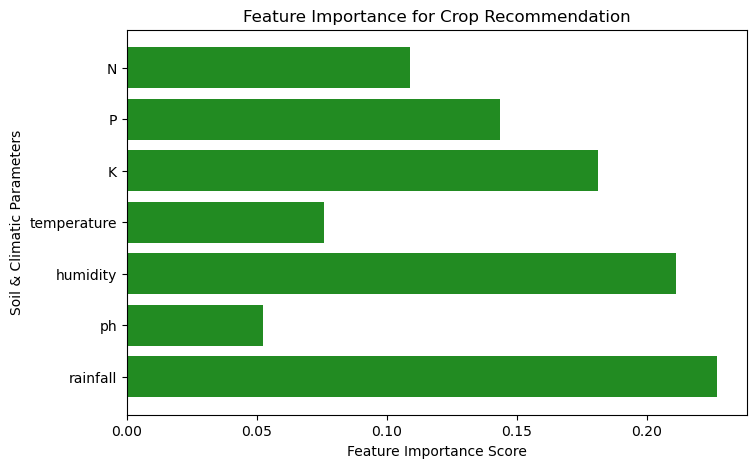

Feature importance graph saved successfully!


In [26]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importances from your trained Random Forest model
importances = best_model.feature_importances_
features = X.columns

# Plot
plt.figure(figsize=(8, 5))
plt.barh(features, importances, color='forestgreen')
plt.xlabel("Feature Importance Score")
plt.ylabel("Soil & Climatic Parameters")
plt.title("Feature Importance for Crop Recommendation")
plt.gca().invert_yaxis()  # Most important at the top
plt.savefig("feature_importance.png", bbox_inches='tight')
plt.show()

print("Feature importance graph saved successfully!")